# Final Data Science Capstone Project
## Leakage-Aware Term-Deposit Campaign Targeting

**Business problem:** rank clients by pre-call subscription likelihood so a campaign manager can allocate limited outbound-call capacity more efficiently.

**Source:** UCI Bank Marketing, `bank-additional-full.csv`, 41,188 date-ordered records from Portuguese bank campaigns, May 2008–November 2010. DOI: [10.24432/C5K306](https://doi.org/10.24432/C5K306), CC BY 4.0.

## 1. Scope and prediction contract
The prediction is made **before the call**. Call `duration` is known only after the call ends and is excluded from the deployable model. The project is a ranking prototype, not an autonomous decision system.

In [1]:
from pathlib import Path
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import *
from IPython.display import display, Image
ROOT=Path('..')
RAW=ROOT/'data/raw/bank-additional/bank-additional-full.csv'
CLEAN=ROOT/'data/processed/bank_marketing_cleaned.csv'
pd.set_option('display.float_format',lambda v:f'{v:,.4f}')
print('pandas',pd.__version__,'numpy',np.__version__)

pandas 2.2.3 numpy 2.3.5


## 2. Raw-data inspection

In [2]:
raw=pd.read_csv(RAW,sep=';')
print(f'Raw dimensions: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
print('Exact duplicates:',raw.duplicated().sum())
print('Null cells:',raw.isna().sum().sum())
print('Semantic unknown values:',(raw.select_dtypes('object')=='unknown').sum().sum())
display(raw.head())

Raw dimensions: 41,188 rows × 21 columns
Exact duplicates: 12
Null cells: 0
Semantic unknown values: 12718


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",no


## 3. Cleaned data and engineered features
Unknown categories are retained as information rather than treated as null. `pdays=999` is converted into a missing `days_since_previous` plus an explicit previously-contacted flag. Outliers are not removed automatically.

In [3]:
df=pd.read_csv(CLEAN)
print(f'Clean dimensions: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('Subscription rate:',f'{df.subscribed.mean():.2%}')
display(df[['age','job','campaign','pdays','previously_contacted','contact_pressure','subscribed']].head())

Clean dimensions: 41,188 rows × 28 columns
Subscription rate: 11.27%


,age,job,campaign,pdays,previously_contacted,contact_pressure,subscribed
0,56,housemaid,1,999,0,1,0
1,57,services,1,999,0,1,0
2,37,services,1,999,0,1,0
3,40,admin.,1,999,0,1,0
4,56,services,1,999,0,1,0


## 4. Exploratory analysis

In [4]:
display(pd.read_csv(ROOT/'outputs/tables/segment_conversion_rates.csv').query("feature in ['job','contact','poutcome']").sort_values(['feature','conversion_rate'],ascending=[True,False]).groupby('feature').head(6))

,feature,segment,campaign_records,subscriptions,conversion_rate
22,contact,cellular,26144,3853,0.1474
23,contact,telephone,15044,787,0.0523
8,job,student,875,275,0.3143
5,job,retired,1720,434,0.2523
10,job,unemployed,1014,144,0.1420
0,job,admin.,10422,1352,0.1297
4,job,management,2924,328,0.1122
11,job,unknown,330,37,0.1121
26,poutcome,success,1373,894,0.6511
24,poutcome,failure,4252,605,0.1423


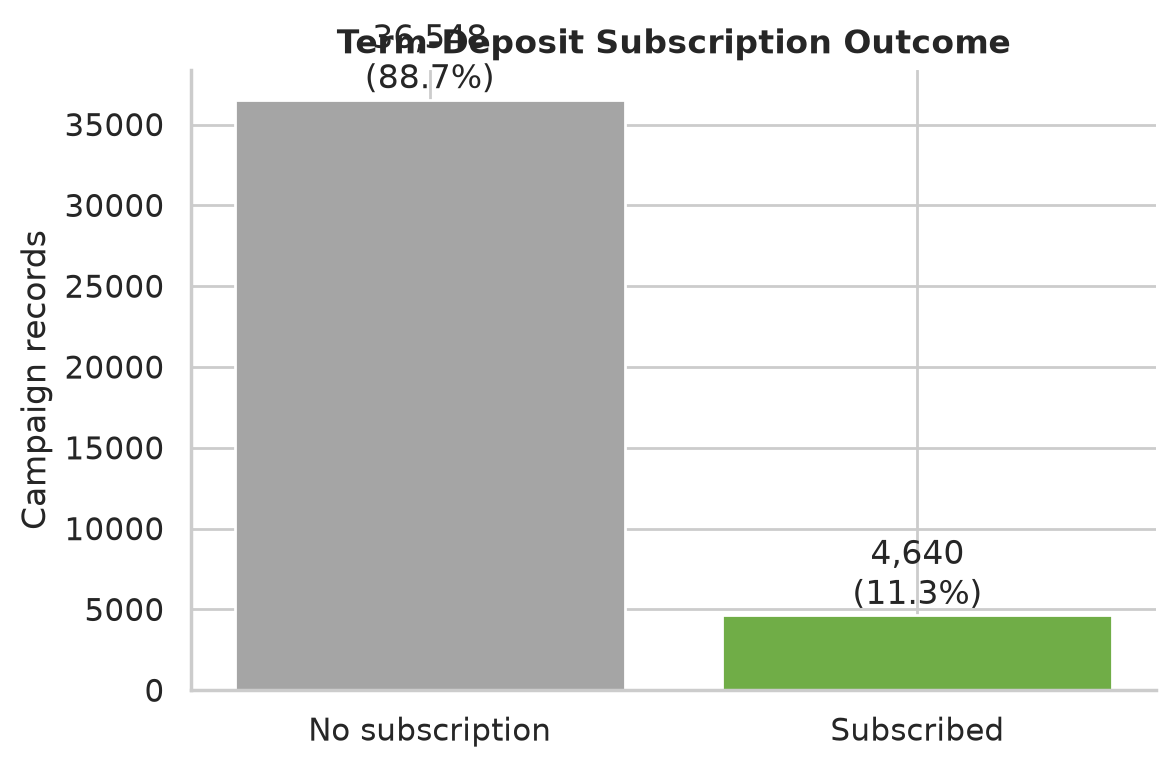

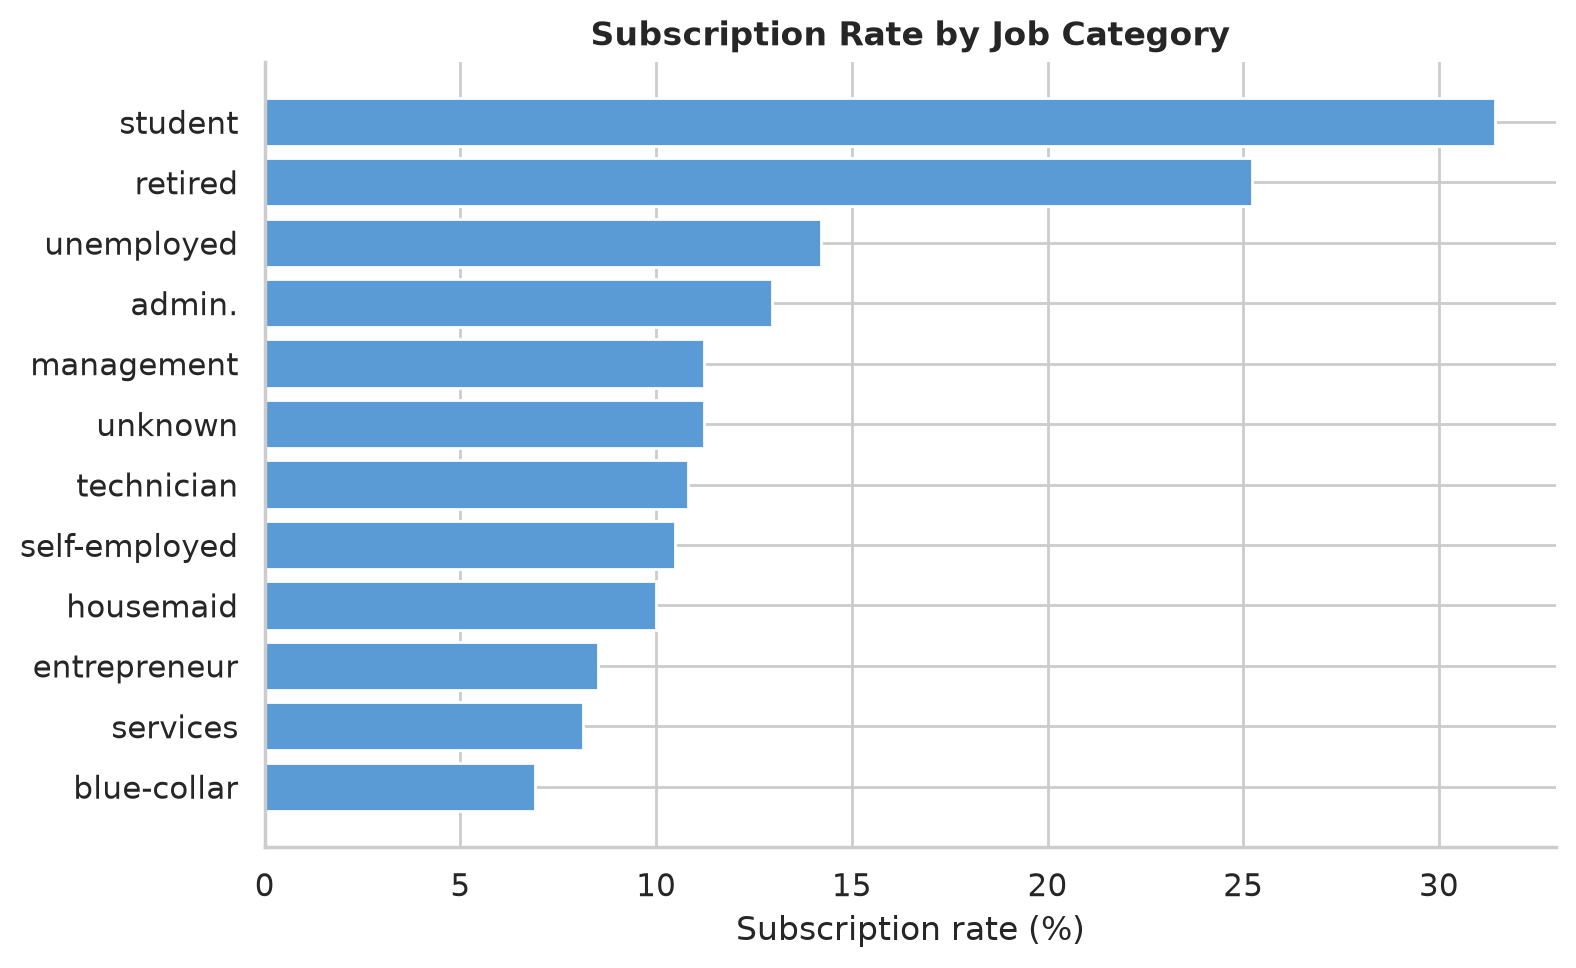

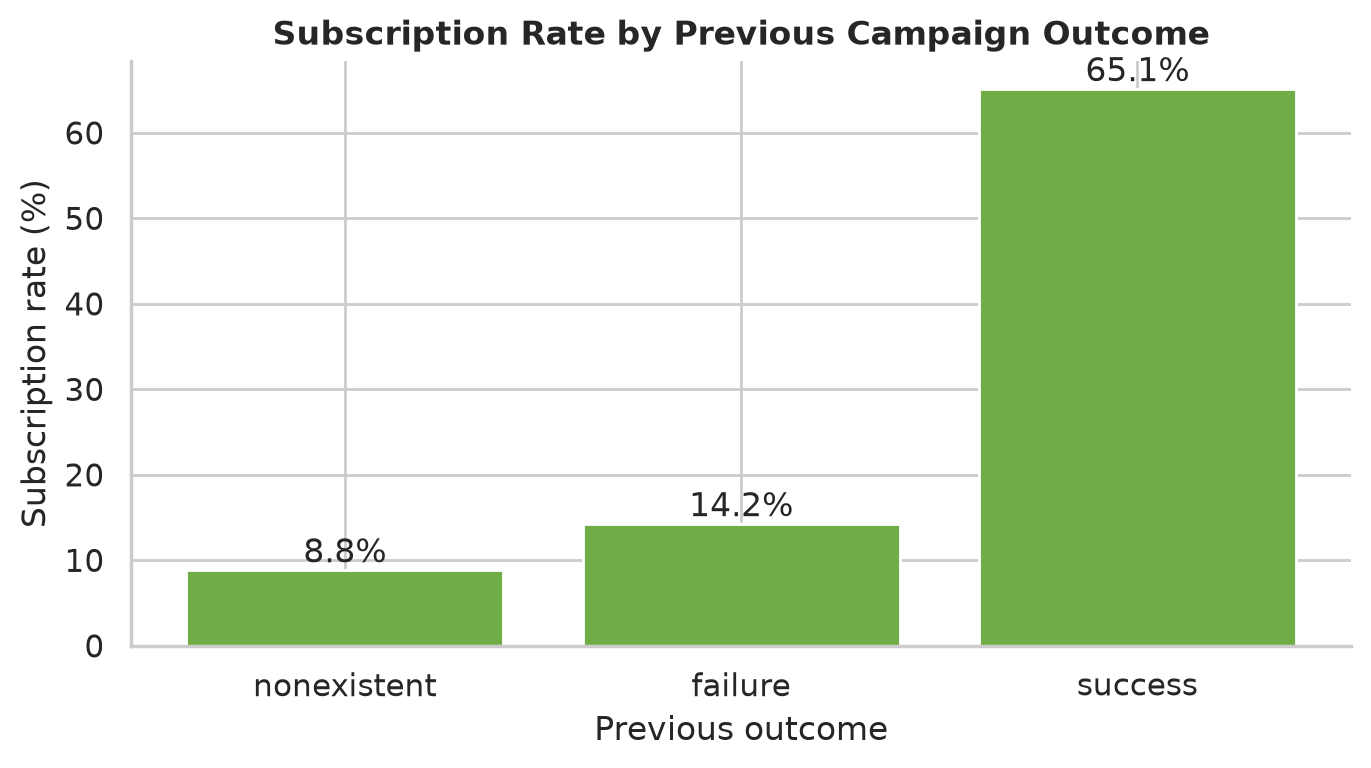

In [5]:
display(Image(filename=str(ROOT/'outputs/charts/01_target_balance.png')))
display(Image(filename=str(ROOT/'outputs/charts/03_job_conversion.png')))
display(Image(filename=str(ROOT/'outputs/charts/04_previous_outcome.png')))

## 5. Leakage-aware temporal evaluation
The source is ordered by date. The first 70% is training, the next 15% validation and the final 15% test. This is harder and more realistic than random shuffling because campaign conditions change over time.

In [6]:
splits=pd.read_csv(ROOT/'outputs/tables/split_summary.csv'); display(splits)
print('The sharp prevalence shift is a model-risk finding, not a preprocessing error.')

,split,start_row,end_row,rows,positives,positive_rate_pct
0,Train,0,28830,28831,1606,5.5704
1,Validation,28831,35008,6178,658,10.6507
2,Test,35009,41187,6179,2376,38.4528


The sharp prevalence shift is a model-risk finding, not a preprocessing error.


## 6. Model comparison
Three deployable candidates are compared on the chronological validation set: class-weighted logistic regression, random forest and histogram gradient boosting. PR-AUC is the primary selection metric because the validation target is imbalanced.

,model,roc_auc,pr_auc,precision,recall,f1,top20_lift
0,Histogram gradient boosting,0.6579,0.2201,0.0000,0.0000,0.0000,1.9386
1,Random forest,0.6286,0.1977,0.1252,0.7690,0.2153,1.8246
2,Logistic regression,0.6479,0.1882,0.1198,0.9088,0.2116,1.9234


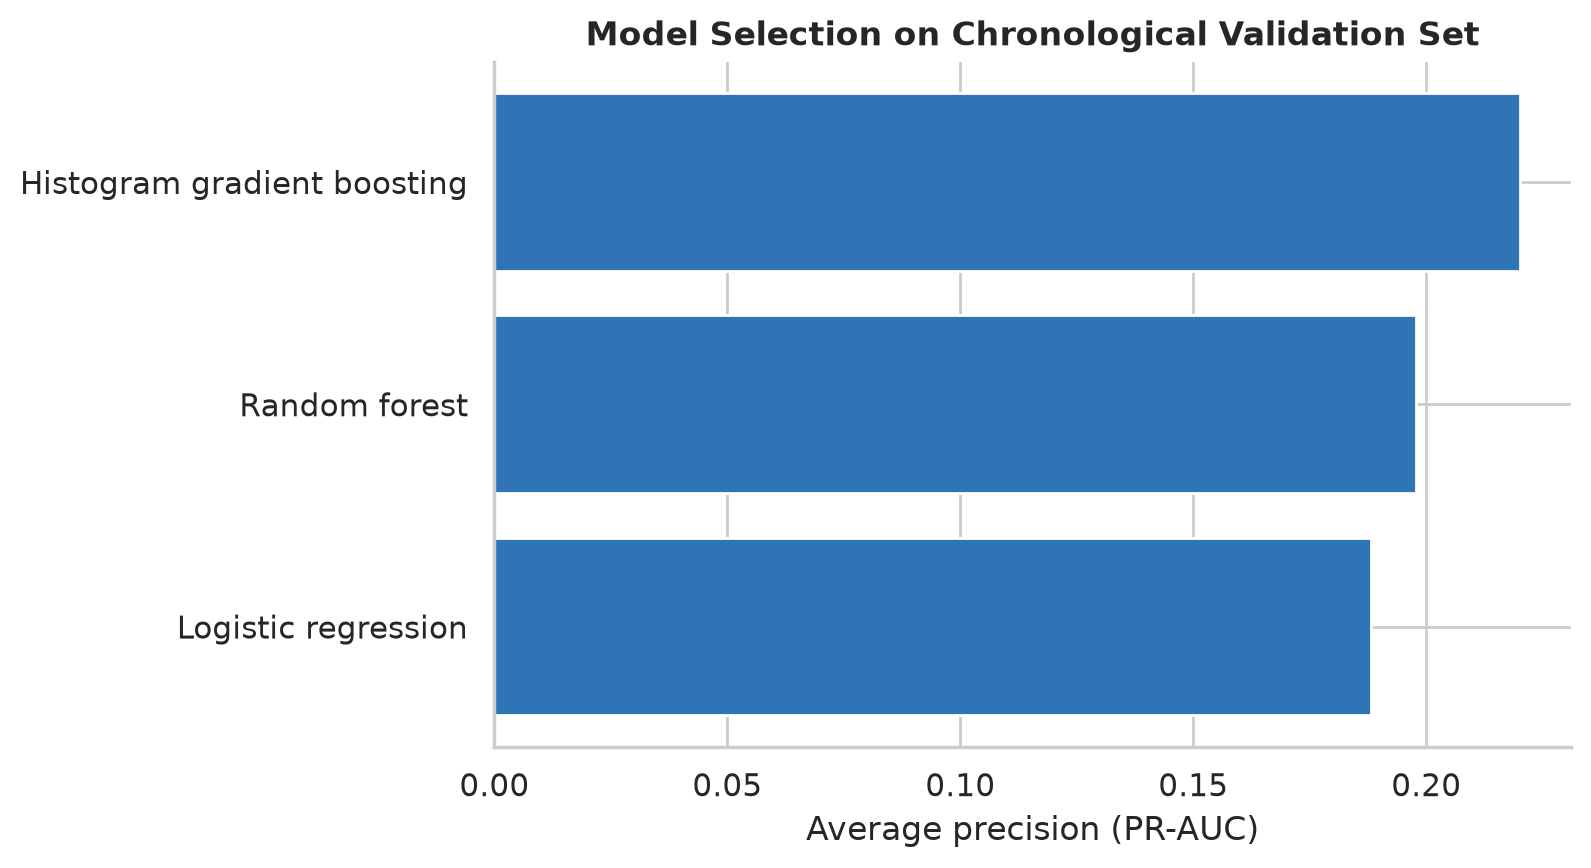

In [7]:
val=pd.read_csv(ROOT/'outputs/tables/validation_model_comparison.csv'); display(val[['model','roc_auc','pr_auc','precision','recall','f1','top20_lift']])
display(Image(filename=str(ROOT/'outputs/charts/06_model_comparison.png')))

## 7. Held-out test performance

In [8]:
summary=json.loads((ROOT/'outputs/summaries/model_summary.json').read_text())
test=pd.read_csv(ROOT/'outputs/tables/test_model_performance.csv')
display(test[['model','threshold','roc_auc','pr_auc','precision','recall','f1','brier','top20_lift']])
print(json.dumps(summary,indent=2))

,model,threshold,roc_auc,pr_auc,precision,recall,f1,brier,top20_lift
0,Prevalence baseline,0.5000,0.5000,0.3845,0.0000,0.0000,0.0000,0.3390,0.3727
1,Histogram gradient boosting,0.5000,0.6345,0.5133,0.6786,0.0720,0.1301,0.2846,1.3456
2,Histogram gradient boosting (validation-tuned ...,0.1008,0.6345,0.5133,0.5082,0.5581,0.5320,0.2846,1.3456


{
  "selected_model": "Histogram gradient boosting",
  "threshold": 0.10075361558734351,
  "raw_rows": 41188,
  "overall_positive_rate_pct": 11.265417111780131,
  "train_rows": 28831,
  "validation_rows": 6178,
  "test_rows": 6179,
  "test_positive_rate_pct": 38.4528240815666,
  "test_roc_auc": 0.6345383672822537,
  "test_pr_auc": 0.5133059792651181,
  "test_default_f1": 0.13013698630136986,
  "test_tuned_precision": 0.508240705251054,
  "test_tuned_recall": 0.5580808080808081,
  "test_tuned_f1": 0.5319959879638917,
  "test_brier": 0.28457808413529573,
  "top20_lift": 1.3455680284627654,
  "top20_subscribers": 639,
  "top20_contacts": 1235,
  "test_subscribers": 2376,
  "leakage_roc_auc": 0.6969914988255772,
  "leakage_pr_auc": 0.5689230825548992
}


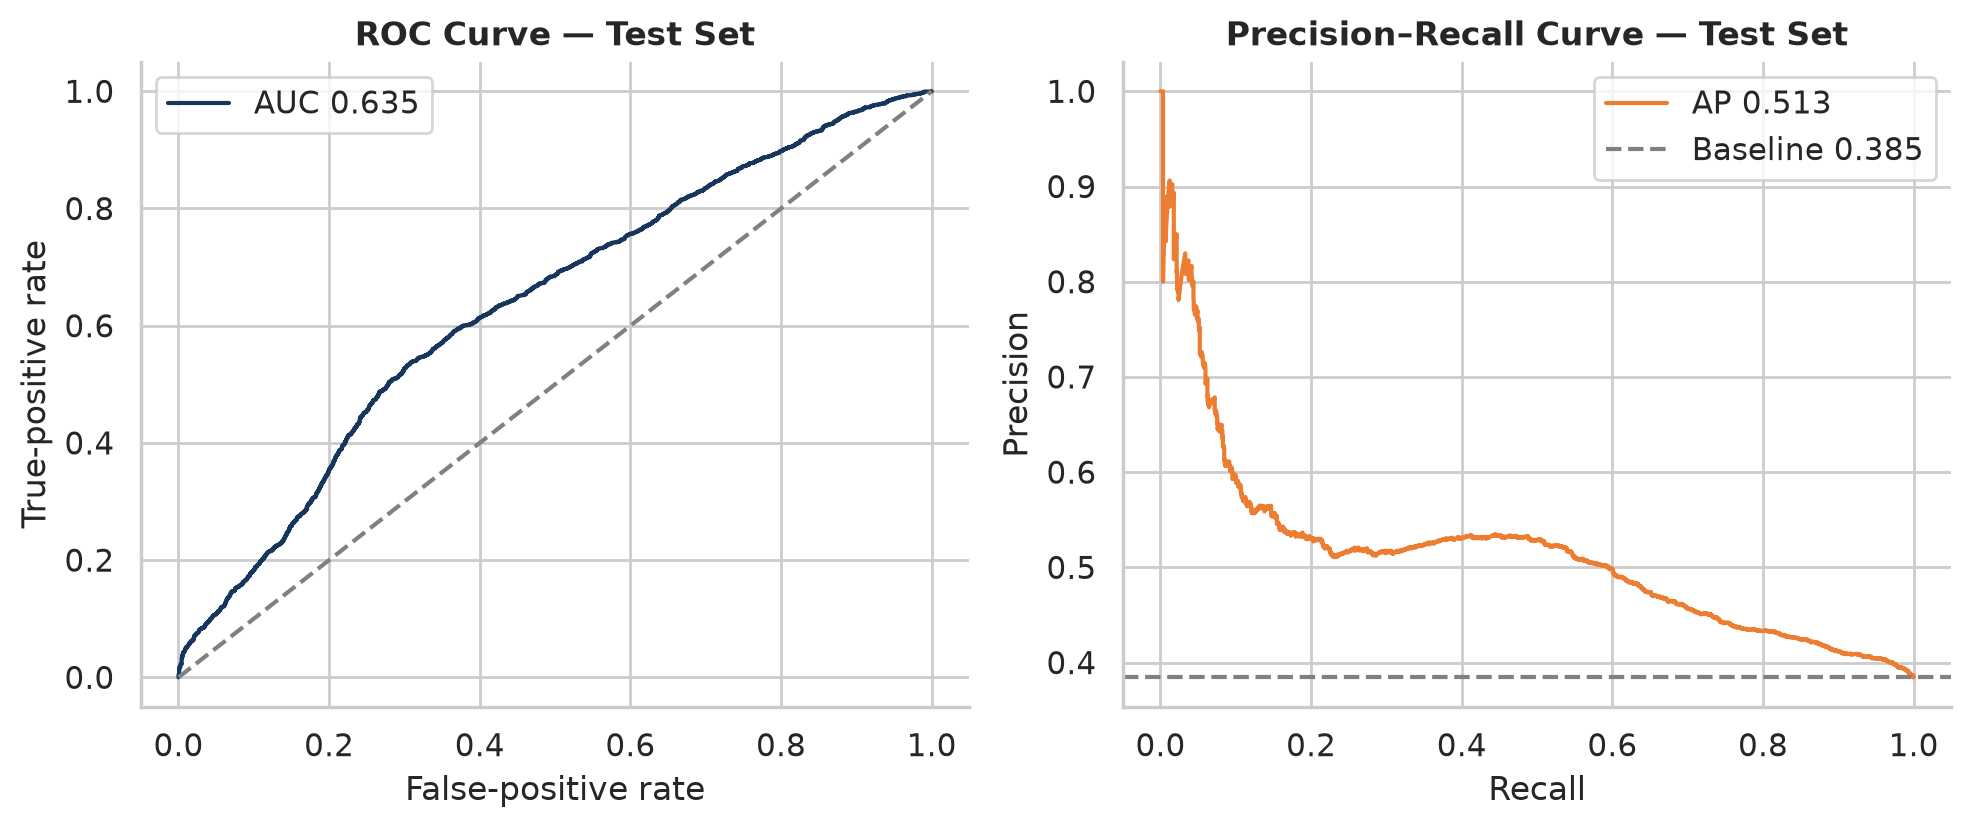

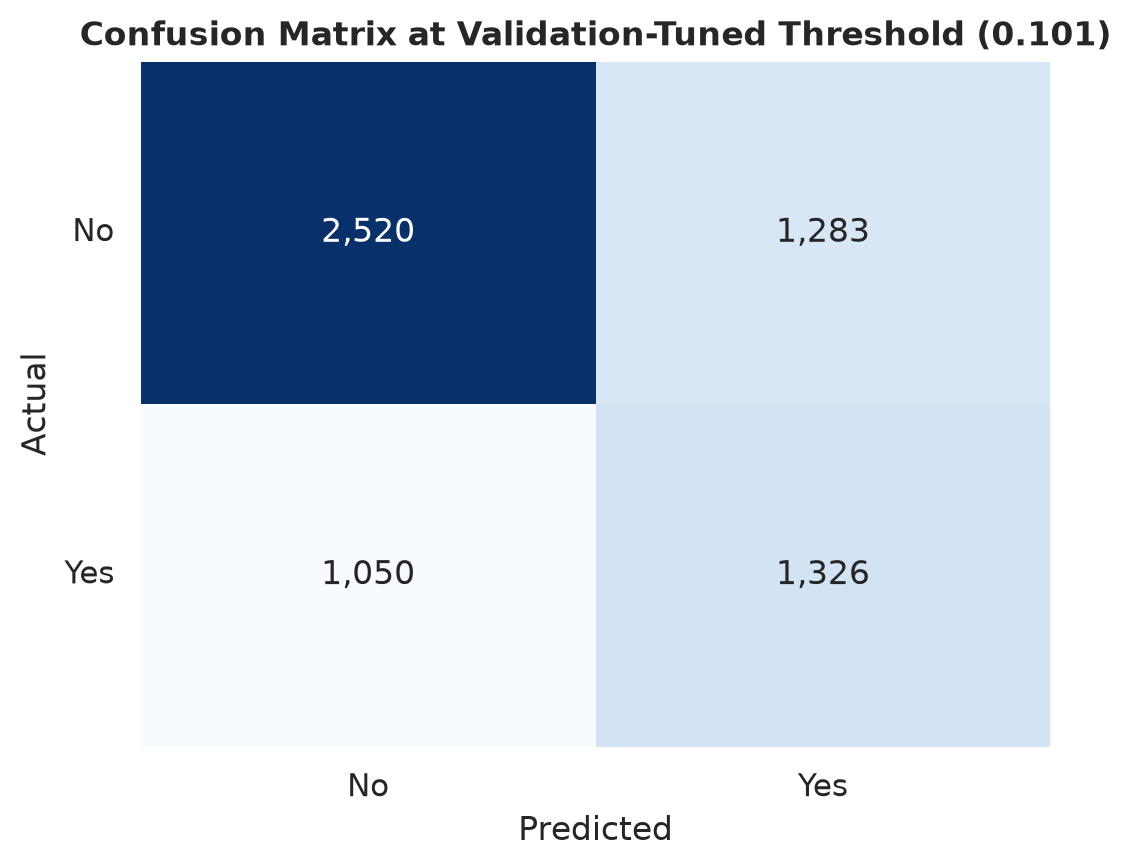

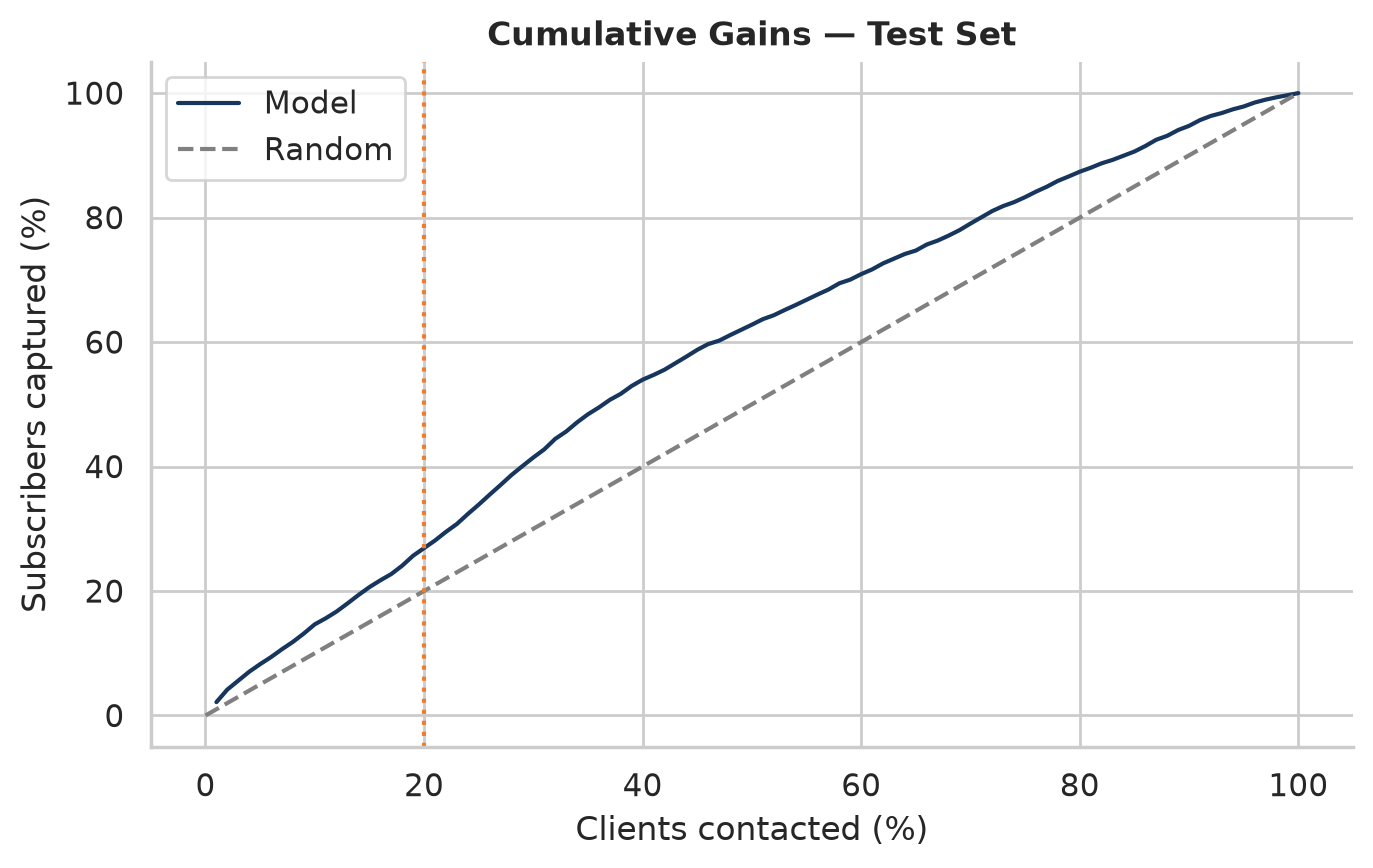

In [9]:
display(Image(filename=str(ROOT/'outputs/charts/07_roc_pr_curves.png')))
display(Image(filename=str(ROOT/'outputs/charts/08_confusion_matrix.png')))
display(Image(filename=str(ROOT/'outputs/charts/09_cumulative_gains.png')))

## 8. Leakage demonstration
The duration-inclusive model is diagnostic only. Its better score demonstrates how a realistic-looking model can be invalid at the actual decision point.

,model,roc_auc,pr_auc
0,Deployable model (duration excluded),0.6345,0.5133
1,Diagnostic leakage model (duration included),0.6970,0.5689


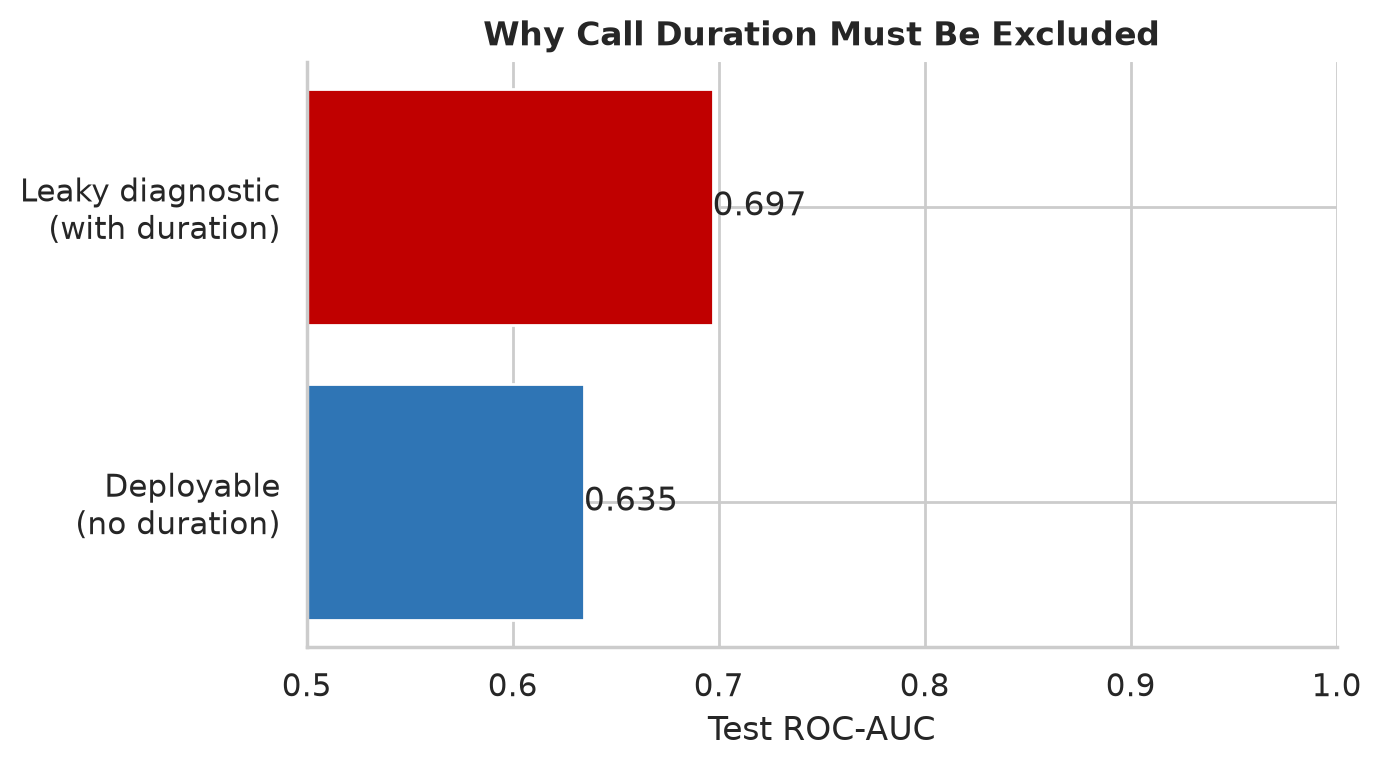

In [10]:
display(pd.read_csv(ROOT/'outputs/tables/leakage_demonstration.csv'))
display(Image(filename=str(ROOT/'outputs/charts/12_leakage_demo.png')))

## 9. Explainability and error analysis

,feature,importance_mean,importance_std
0,pdays,0.0773,0.0041
1,month,0.0433,0.0061
2,age,0.0117,0.0028
3,contact,0.0116,0.0024
4,day_of_week,0.0084,0.0019
5,poutcome,0.0055,0.0019
6,days_since_previous,0.0024,0.0007
7,has_credit_obligation,0.0023,0.0012
8,previously_contacted,0.0021,0.0002
9,job,0.0011,0.0015


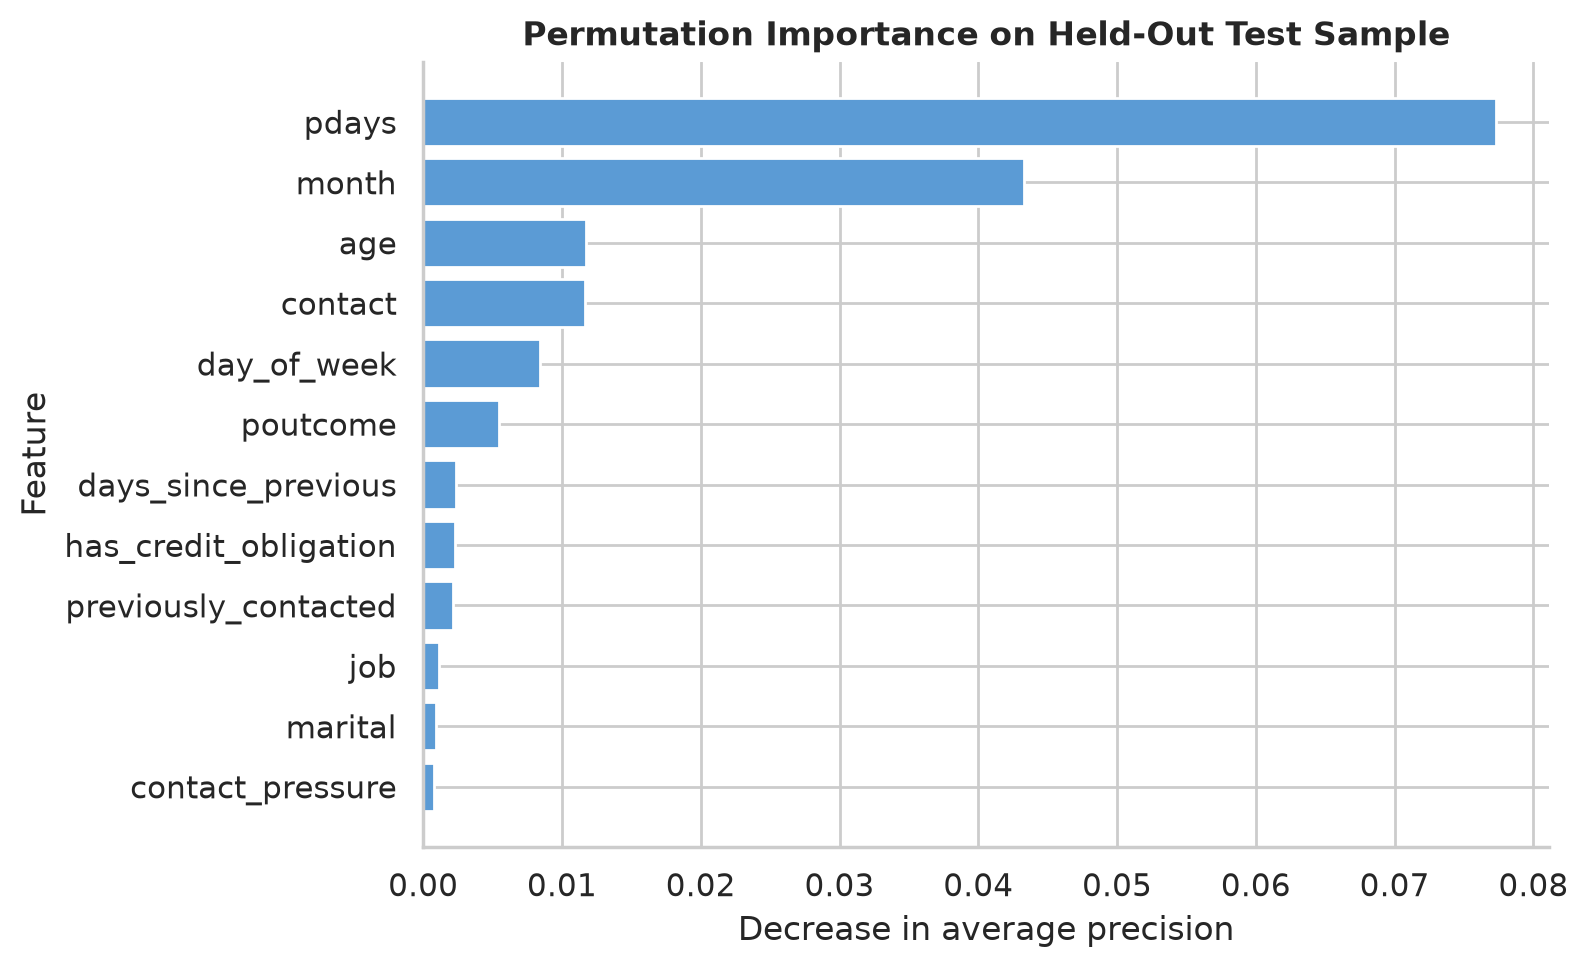

In [11]:
imp=pd.read_csv(ROOT/'outputs/tables/permutation_importance.csv'); display(imp.head(12))
display(Image(filename=str(ROOT/'outputs/charts/10_feature_importance.png')))

error_type
Correct           3846
False positive    1283
False negative    1050
Name: count, dtype: int64


,age_band,rows,positive_rate_pct,selection_rate_pct,precision,recall,false_positive_rate
0,<30,1411,38.8377,47.2714,0.4933,0.6004,0.3917
1,30–39,2077,36.2542,36.8801,0.5170,0.5259,0.2795
2,40–49,982,35.0305,26.4766,0.5808,0.4390,0.1708
3,50–59,864,39.6991,41.7824,0.4848,0.5102,0.3570
4,60–69,447,43.4004,65.3244,0.4692,0.7062,0.6126
5,70+,398,48.7437,66.0804,0.5247,0.7113,0.6127


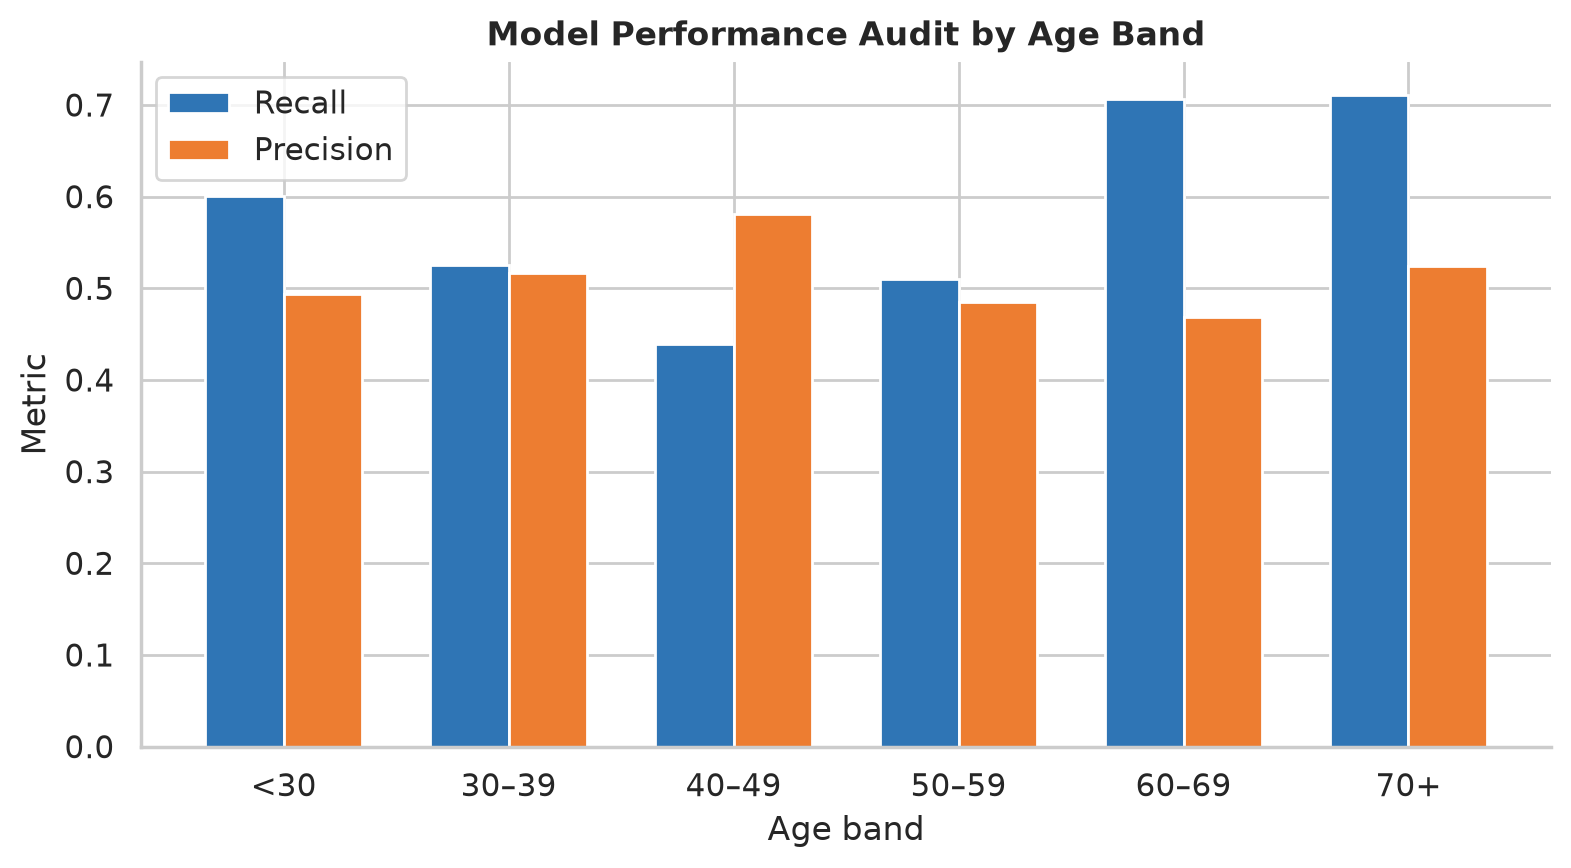

In [12]:
scored=pd.read_csv(ROOT/'outputs/tables/test_scored_predictions.csv')
print(scored.error_type.value_counts())
display(pd.read_csv(ROOT/'outputs/tables/age_band_model_audit.csv'))
display(Image(filename=str(ROOT/'outputs/charts/13_age_band_audit.png')))

## 10. Statistical observations
Previous campaign outcome is associated with subscription (chi-square p < 0.001). Current campaign contact count is negatively associated with subscription, but neither relationship proves a causal intervention effect.

In [13]:
tests=json.loads((ROOT/'outputs/summaries/statistical_tests.json').read_text()); print(json.dumps(tests,indent=2))

{
  "poutcome_chi_square": 4230.5237978319765,
  "poutcome_p_value": 0.0,
  "poutcome_dof": 2,
  "campaign_contacts_spearman_rho": -0.06366813979420918,
  "campaign_contacts_p_value": 2.8910138996596117e-38
}


## 11. Insights and recommendations

In [14]:
display(pd.read_csv(ROOT/'outputs/tables/insights_table.csv'))
display(pd.read_csv(ROOT/'outputs/tables/recommendation_matrix.csv')[['recommendation','priority','success_kpi']])

,business_area,finding,evidence,business_meaning,evidence_type
0,Target balance,Only 11.2654171117801311652328877% of all reco...,"4,640 positives of 41,188",Accuracy alone is misleading; ranking and PR m...,Observed
1,Temporal drift,Subscription prevalence changes sharply across...,Train 5.57%; validation 10.65%; test 38.45%,A static model is poorly calibrated across cam...,Observed
2,Model discrimination,The selected histogram gradient boosting model...,Test ROC-AUC 0.635; PR-AUC 0.513 vs test preva...,"Useful for prioritisation, not automatic rejec...",Observed
3,Targeting lift,The top-scored 20% of test records contain 639...,26.89% of test subscribers captured; lift 1.35,Ranking can concentrate likely responders when...,Observed
4,Threshold trade-off,Validation-tuned threshold 0.101 balances prec...,Precision 0.508; recall 0.558; F1 0.532,"Threshold must be set from campaign economics,...",Observed
5,Leakage,Using call duration improves apparent scores b...,ROC-AUC rises from 0.635 to 0.697,A duration-based pre-call model would be inval...,Observed
6,Previous outcomes,A prior successful campaign is strongly associ...,Previous-success conversion 65.11%; chi-square...,"Prior engagement is a useful ranking signal, b...",Observed association
7,Contact channel,Cellular-contact records convert more often th...,Cellular 14.74%; telephone 5.23%,Could reflect campaign period/client mix; chan...,Observed association
8,Contact pressure,More current-campaign contacts are negatively ...,"Spearman rho -0.064, p < 0.001",Repeated contacts may signal hard-to-convert p...,Observed association
9,Age audit,Precision/recall and selection rates vary acro...,Recall ranges from 0.439 to 0.711; older bands...,Human oversight and subgroup monitoring are ne...,Observed


,recommendation,priority,success_kpi
0,Use the model only as a ranked pilot,High,Subscriber capture per 100 calls; contact cost...
1,Monitor temporal drift and recalibrate,High,PR-AUC/prevalence ratio; Brier score; calibrat...
2,Define threshold from campaign economics,High,Net contribution per contacted client; capacit...
3,Keep duration out of all pre-call scoring,High,Zero post-outcome features in production schema
4,Use prior-campaign success carefully,Medium,Incremental subscription rate; opt-out rate
5,Test contact policy rather than infer causality,Medium,Incremental conversion; complaints; cost per s...
6,Implement responsible-model controls,High,"Selection, precision, recall and FPR by approv..."
7,Improve the data layer,Long term,Data completeness; reproducible time split; ca...


## 12. Limitations and future scope
- Strong temporal drift and poor absolute calibration.
- No client ID, so repeated clients cannot be grouped across splits.
- Historic Portuguese data may not generalise to another country or current campaigns.
- Observational associations are not causal effects.
- Age-band audit is not a complete fairness assessment.
- Deployment requires consent, legal review, monitoring, economic thresholding and a current pilot.

**Conclusion:** the model is suitable for a controlled ranking pilot, not autonomous production use.